# ResNet Model Evaluation on Test Dataset

In [1]:
import torch
from torch import nn
from torchvision import models
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchmetrics.classification import (
    MulticlassAccuracy,
    MulticlassPrecision,
    MulticlassRecall,
    MulticlassF1Score,
    MulticlassConfusionMatrix
)
import matplotlib.pyplot as plt

torch.manual_seed(42)

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")

Device: cuda


In [2]:
test_dataset = ImageFolder(
    "../dataset/test",
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [3]:
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, out_features=10)

model.load_state_dict(
    torch.load("../models/ResNet_FT.pt")
)

model = model.to(device)

In [4]:
def evaluate_model(model, dataloader, device):

    accuracy = MulticlassAccuracy(num_classes=10).to(device)
    precision = MulticlassPrecision(num_classes=10).to(device)
    recall = MulticlassRecall(num_classes=10).to(device)
    f1 = MulticlassF1Score(num_classes=10, average="macro").to(device)

    model.eval()
    with torch.inference_mode():

        for images, labels in dataloader:

            images, labels = images.to(device), labels.to(device)
            outputs = model(images)

            accuracy.update(outputs, labels)
            precision.update(outputs, labels)
            recall.update(outputs, labels)
            f1.update(outputs, labels)

    results = {
        "accuracy": accuracy.compute().item(),
        "precision": precision.compute().item(),
        "recall": recall.compute().item(),
        "f1": f1.compute().item()
    }

    return results

results = evaluate_model(model, test_loader, device)
print(f"Results :-\n{results}")

Results :-
{'accuracy': 0.9337718486785889, 'precision': 0.931003749370575, 'recall': 0.9337718486785889, 'f1': 0.9318301677703857}


In [5]:
class_names = test_dataset.classes
def get_confusion_matrix(model, dataloader, device):

    cm = MulticlassConfusionMatrix(num_classes=10).to(device)

    model.eval()
    with torch.inference_mode():

        for images, labels in dataloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            cm.update(outputs, labels)

    return cm

cm = get_confusion_matrix(model, test_loader, device)

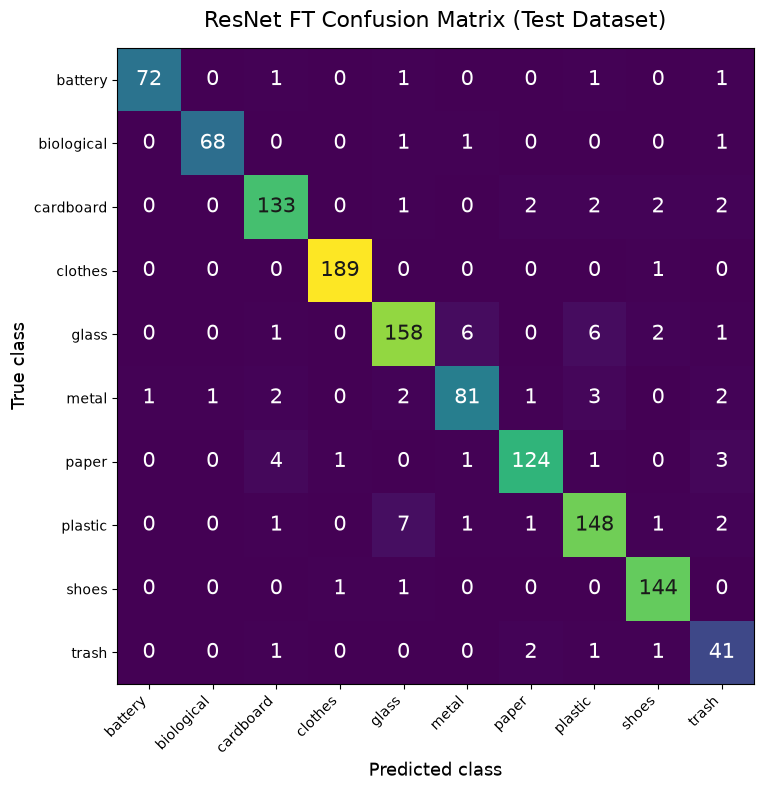

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))

cm.plot(labels=class_names, ax=ax)

ax.set_title("ResNet FT Confusion Matrix (Test Dataset)", fontsize=16, pad=15)
ax.set_xlabel("Predicted class", fontsize=13)
ax.set_ylabel("True class", fontsize=13)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

plt.setp(
    ax.get_yticklabels(),
    rotation=0
)

plt.tight_layout()
plt.show()